# N-dim RNN periodic counting task

Train an $N$-dimensional RNN to track position within a repeating reward cycle.

**Model:** $h_t = \mathrm{clip}(W_{\rm rec}\, h_{t-1} + w_{\rm in}\, r_t + g_t\, h^* + b,\,-1,1)$, $\quad y_t = \mathrm{CSM}(k\,(w_{\rm out} \cdot h_t) + \theta)$

**Input:** $r_t \sim \mathrm{Bernoulli}(p)$ i.i.d.; $g_t$ = gate signal.

**Target:** $y^*_t = \mathbf{1}\!\left[\left(\textstyle\sum_{t' \leq t} r_{t'}\right) \bmod C \;\geq\; n^*\right]$

where $C$ is the cycle length (number of rewards per period) and $n^*$ is the within-cycle threshold.

**Loss:** MSE averaged over all $T$ timesteps.

In [6]:
import jax
import jax.numpy as jnp
from jax import random
import optax
import matplotlib.pyplot as plt
import numpy as np

# jax.config.update('jax_platforms', 'cpu')

In [16]:
# ── Task & training hyperparameters ──────────────────────────────────────────
T = 100
N_CYCLE      = 20      # rewards per period C
N_THRESHOLD  = 10      # fire when (cumsum % N_CYCLE) >= N_THRESHOLD (first half)
N_THRESHOLD_2= 12      # threshold for second half of training
HIDDEN_SIZE  = 10     # RNN hidden dimension
DELAY        = 5     # max delay; each trial gets Uniform[0, DELAY] silent timesteps
P            = 0.3    # Bernoulli input probability
BATCH_SIZE   = 64
N_STEPS      = 100_000
LR           = 1e-3
LR_2         = 1e-4   # learning rate after LR_SWITCH_STEP
LR_SWITCH_STEP = 40_000
L2_H         = 0
L2_W         = 0
RECORD_EVERY = 100
SEED         = 11
UNIT_NOISE_STD = 0.005

In [17]:
jax.clear_caches()
key = random.PRNGKey(SEED)
key = random.split(key)[0]
# ── Model ────────────────────────────────────────────────────────────────────

@jax.custom_vjp
def heaviside_ste(x):
    return jnp.heaviside(x, 0.5)

def _ste_fwd(x):
    return heaviside_ste(x), x

def _ste_bwd(x, g):
    sig = jax.nn.sigmoid(x)
    return (g * sig * (1.0 - sig),)

heaviside_ste.defvjp(_ste_fwd, _ste_bwd)


def cubic_smoothstep(x, a=1.0):
    t = jnp.clip((x + a) / (2.0 * a), 0.0, 1.0)
    return 3.0 * t ** 2 - 2.0 * t ** 3


def init_params(key, scale=0.05):
    k1, k2, k3, k4, k5, k6, k7 = random.split(key, 7)
    return dict(
        W_rec     =random.normal(k1, (HIDDEN_SIZE, HIDDEN_SIZE)) * scale,
        w_in      =random.normal(k2, (HIDDEN_SIZE,)) * scale,
        b         =jnp.zeros((HIDDEN_SIZE,)),
        h_star    =random.normal(k4, (HIDDEN_SIZE,)) * scale,
        threshold =random.normal(k5, ()) * scale,
        steepness =random.normal(k6, ()) * scale,
        w_out     =random.normal(k7, (HIDDEN_SIZE,)) * scale,
    )


def forward_single(params, inputs):
    def step(h, x):
        h_new = params['W_rec'] @ h + params['w_in'] * x[0] + x[1] * params['h_star'] + params['b']
        h_new = jnp.minimum(jnp.maximum(h_new, 0), 1.0)
        z = params['w_out'] @ h_new
        y = cubic_smoothstep(params['steepness'] * z + params['threshold'])
        return h_new, (y, h_new)
    h0 = jnp.zeros(HIDDEN_SIZE)
    _, (ys, hs) = jax.lax.scan(step, h0, inputs)
    return ys, hs

forward_batch = jax.vmap(forward_single, in_axes=(None, 0))


def forward_single_noisy(params, inputs, noise):
    def step(h, x_n):
        x, n = x_n
        h_new = params['W_rec'] @ h + params['w_in'] * x[0] + x[1] * params['h_star'] + params['b']
        h_new = jnp.minimum(jnp.maximum(h_new + n, -1.0), 1.0)
        z = params['w_out'] @ h_new
        y = cubic_smoothstep(params['steepness'] * z + params['threshold'], a=0.1)
        return h_new, (y, h_new)
    h0 = jnp.zeros(HIDDEN_SIZE)
    _, (ys, hs) = jax.lax.scan(step, h0, (inputs, noise))
    return ys, hs

forward_batch_noisy = jax.vmap(forward_single_noisy, in_axes=(None, 0, 0))


def targets(inputs_batch, n_threshold):
    """Binary target: 1 when (cumulative reward count % N_CYCLE) >= n_threshold."""
    cum = jnp.cumsum(inputs_batch[:, :, 0], axis=1)
    return ((cum % N_CYCLE) >= n_threshold).astype(jnp.float32)


def loss_fn(params, inputs_batch, n_threshold, key, noise_std=UNIT_NOISE_STD, l2_h=0.0):
    noise = random.normal(key, shape=(inputs_batch.shape[0], inputs_batch.shape[1], HIDDEN_SIZE)) * noise_std
    ys, hs  = forward_batch_noisy(params, inputs_batch, noise)
    ys_star = targets(inputs_batch, n_threshold)
    mse     = jnp.mean((ys - ys_star) ** 2)
    l2_act  = l2_h * jnp.mean(hs ** 2)
    l2_par  = L2_W * (
        jnp.mean(params['W_rec']     ** 2) +
        jnp.mean(params['w_in']      ** 2) +
        jnp.mean(params['b']         ** 2) +
        jnp.mean(params['h_star']    ** 2) +
        jnp.mean(params['threshold'] ** 2) +
        jnp.mean(params['steepness'] ** 2) +
        jnp.mean(params['w_out']     ** 2)
    )
    return mse + l2_act + l2_par

def sample_batch(key, batch_size, T, p):
    key_inputs, _ = random.split(key)
    inputs_g = jnp.zeros(shape=(batch_size, T)).astype(jnp.float32)
    inputs_g = inputs_g.at[:, :DELAY].set(1.0)
    inputs_r = random.bernoulli(key_inputs, p, shape=(batch_size, T)).astype(jnp.float32)
    inputs_r = inputs_r.at[:, :DELAY].set(0.0)
    return jnp.stack([inputs_r, inputs_g], axis=-1)  # (batch, T, 2)

In [18]:
# ── Training loop ─────────────────────────────────────────────────────────────
key, init_key = random.split(key)

params    = init_params(init_key, scale=0.05)
lr_schedule = optax.piecewise_constant_schedule(
    init_value=LR,
    boundaries_and_scales={LR_SWITCH_STEP: LR_2 / LR},
)
optimizer = optax.adam(lr_schedule)
opt_state = optimizer.init(params)

@jax.jit
def train_step(params, opt_state, key, n_threshold):
    key, noise_key = random.split(key)
    inputs = sample_batch(key, BATCH_SIZE, T, P)
    loss, grads = jax.value_and_grad(loss_fn)(params, inputs, n_threshold, noise_key, UNIT_NOISE_STD, L2_H)
    updates, new_opt_state = optimizer.update(grads, opt_state)
    new_params = optax.apply_updates(params, updates)
    return new_params, new_opt_state, loss

key, eval_key = random.split(key)

@jax.jit
def eval_mean_proj(params):
    """Mean c·h_t trajectory across a fixed eval batch."""
    inputs = sample_batch(eval_key, BATCH_SIZE, T, P)
    noise = random.normal(eval_key, shape=(BATCH_SIZE, T, HIDDEN_SIZE)) * UNIT_NOISE_STD
    _, hs = forward_batch_noisy(params, inputs, noise)
    return jnp.mean(hs, axis=0)


history = dict(
    loss=[], threshold=[], steepness=[],
    W_rec_00=[], w_in_0=[], b_0=[], h_star_0=[],
)
recorded_proj, recorded_steps = [], []
switch_step = N_STEPS // 2

for step in range(N_STEPS):
    key, subkey = random.split(key)
    n_thresh = N_THRESHOLD if step < switch_step else N_THRESHOLD_2
    params, opt_state, loss = train_step(params, opt_state, subkey, n_thresh)
    W = params['W_rec']
    history['loss'].append(float(loss))
    history['threshold'].append(float(params['threshold']))
    history['steepness'].append(float(params['steepness']))
    history['W_rec_00'].append(float(W[0, 0]))
    history['w_in_0'].append(float(params['w_in'][0]))
    history['b_0'].append(float(params['b'][0]))
    history['h_star_0'].append(float(params['h_star'][0]))
    if step % RECORD_EVERY == 0:
        recorded_proj.append(np.array(eval_mean_proj(params)))
        recorded_steps.append(step)

print(f"Final loss : {history['loss'][-1]:.6f}")
print(f"W_rec      = {float(params['W_rec'][0,0]):.4f}")
print(f"w_in       = {float(params['w_in'][0]):.4f}")
print(f"b          = {float(params['b'][0]):.4f}")
print(f"h_star     = {float(params['h_star'][0]):.4f}")
print(f"threshold  = {float(params['threshold']):.4f}")
print(f"steepness  = {float(params['steepness']):.4f}")


Final loss : 0.022640
W_rec      = 0.1721
w_in       = -0.0215
b          = -0.0676
h_star     = 0.1703
threshold  = -0.5792
steepness  = -0.7059


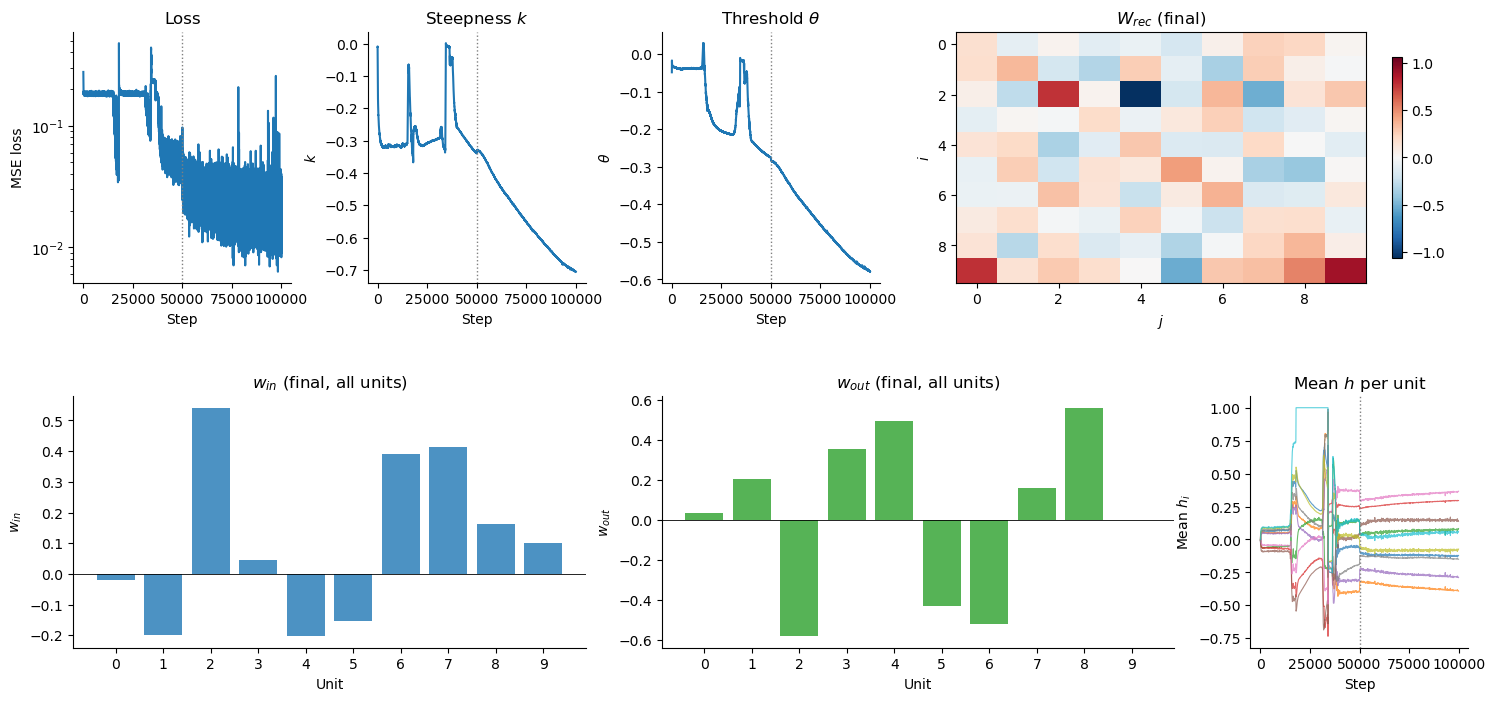

In [19]:
# ── Plot: loss curve and parameter trajectories ───────────────────────────────

steps = np.arange(N_STEPS)
W_rec_final = np.array(params['W_rec'])   # (H, H)
w_in_final  = np.array(params['w_in'])    # (H,)
w_out_final = np.array(params['w_out'])   # (H,)

fig = plt.figure(figsize=(18, 8))
gs  = fig.add_gridspec(2, 5, wspace=0.35, hspace=0.45)

# ── row 0 ──
ax_loss = fig.add_subplot(gs[0, 0])
ax_loss.semilogy(steps, history['loss'])
ax_loss.axvline(switch_step, c='gray', ls=':', lw=1.0)
ax_loss.set_xlabel('Step'); ax_loss.set_ylabel('MSE loss'); ax_loss.set_title('Loss')
ax_loss.spines[['top', 'right']].set_visible(False)

ax_k = fig.add_subplot(gs[0, 1])
ax_k.plot(steps, history['steepness'])
ax_k.axvline(switch_step, c='gray', ls=':', lw=1.0)
ax_k.set_xlabel('Step'); ax_k.set_ylabel('$k$'); ax_k.set_title('Steepness $k$')
ax_k.spines[['top', 'right']].set_visible(False)

ax_thr = fig.add_subplot(gs[0, 2])
ax_thr.plot(steps, history['threshold'])
ax_thr.axvline(switch_step, c='gray', ls=':', lw=1.0)
ax_thr.set_xlabel('Step'); ax_thr.set_ylabel('$\\theta$'); ax_thr.set_title('Threshold $\\theta$')
ax_thr.spines[['top', 'right']].set_visible(False)

ax_wrec = fig.add_subplot(gs[0, 3:5])
im = ax_wrec.imshow(W_rec_final, cmap='RdBu_r', aspect='auto',
                    vmin=-np.abs(W_rec_final).max(), vmax=np.abs(W_rec_final).max())
fig.colorbar(im, ax=ax_wrec, shrink=0.8)
ax_wrec.set_xlabel('$j$'); ax_wrec.set_ylabel('$i$'); ax_wrec.set_title('$W_{rec}$ (final)')

# ── row 1 ──
ax_win = fig.add_subplot(gs[1, 0:2])
x_idx = np.arange(HIDDEN_SIZE)
ax_win.bar(x_idx, w_in_final, color='C0', alpha=0.8)
ax_win.axhline(0, c='k', lw=0.6)
ax_win.set_xlabel('Unit'); ax_win.set_ylabel('$w_{in}$'); ax_win.set_title('$w_{in}$ (final, all units)')
ax_win.set_xticks(x_idx)
ax_win.spines[['top', 'right']].set_visible(False)

ax_wout = fig.add_subplot(gs[1, 2:4])
ax_wout.bar(x_idx, w_out_final, color='C2', alpha=0.8)
ax_wout.axhline(0, c='k', lw=0.6)
ax_wout.set_xlabel('Unit'); ax_wout.set_ylabel('$w_{out}$'); ax_wout.set_title('$w_{out}$ (final, all units)')
ax_wout.set_xticks(x_idx)
ax_wout.spines[['top', 'right']].set_visible(False)

mean_proj = np.stack(recorded_proj).mean(axis=1)   # (n_recorded, H) -> mean over batch -> (n_recorded, H)
ax_proj = fig.add_subplot(gs[1, 4])
for i in range(HIDDEN_SIZE):
    ax_proj.plot(recorded_steps, np.stack(recorded_proj)[:, :, i].mean(axis=1),
                 lw=0.8, alpha=0.7)
ax_proj.axvline(switch_step, c='gray', ls=':', lw=1.0)
ax_proj.set_xlabel('Step'); ax_proj.set_ylabel('Mean $h_i$')
ax_proj.set_title('Mean $h$ per unit')
ax_proj.spines[['top', 'right']].set_visible(False)

plt.show()

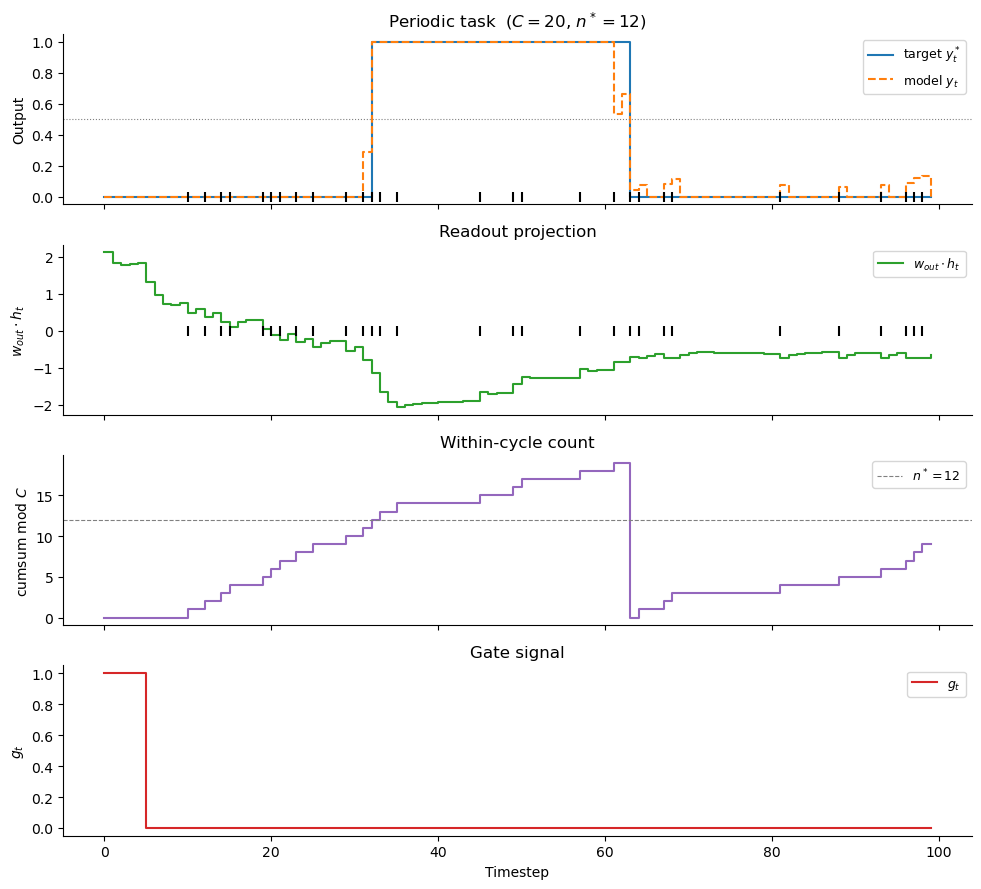

In [21]:
# ── Plot: example sequence ────────────────────────────────────────────────────

key, ex_key, ex_noise_key = random.split(key, 3)
ex_inputs = sample_batch(ex_key, 1, T, P)[0]                 # (T, 2)
ex_noise = random.normal(ex_noise_key, shape=(T, HIDDEN_SIZE)) * UNIT_NOISE_STD
ex_pred, ex_hs = forward_single_noisy(params, ex_inputs, ex_noise)
w_out_np = np.array(params['w_out'])
ex_h = np.array(ex_hs) @ w_out_np                              # (T,) projected readout
ex_inputs_r = ex_inputs[:, 0]
ex_inputs_g = ex_inputs[:, 1]
ex_cum = np.cumsum(np.array(ex_inputs_r))
ex_target = ((ex_cum % N_CYCLE) >= N_THRESHOLD_2).astype(np.float32)

fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
t = np.arange(T)
input_ticks = t[np.array(ex_inputs_r) > 0]

ax = axes[0]
ax.step(t, ex_target, where='post', label='target $y^*_t$', lw=1.5)
ax.step(t, np.array(ex_pred), where='post', label='model $y_t$', lw=1.5, ls='--')
ax.scatter(input_ticks, np.zeros(len(input_ticks)), marker='|', s=60, c='k', zorder=3)
ax.axhline(0.5, ls=':', c='gray', lw=0.8)
ax.set_ylabel('Output')
ax.set_title(f'Periodic task  ($C={N_CYCLE}$, $n^*={N_THRESHOLD_2}$)')
ax.legend(fontsize=9); ax.spines[['top', 'right']].set_visible(False)

ax = axes[1]
ax.step(t, ex_h, where='post', color='C2', lw=1.5, label='$w_{out} \cdot h_t$')
ax.scatter(input_ticks, np.zeros(len(input_ticks)), marker='|', s=60, c='k', zorder=3)
ax.set_ylabel('$w_{out} \cdot h_t$'); ax.set_title('Readout projection')
ax.legend(fontsize=9); ax.spines[['top', 'right']].set_visible(False)

ax = axes[2]
ax.step(t, ex_cum % N_CYCLE, where='post', color='C4', lw=1.5)
ax.axhline(N_THRESHOLD_2, ls='--', c='gray', lw=0.8, label=f'$n^*={N_THRESHOLD_2}$')
ax.set_ylabel('cumsum mod $C$'); ax.set_title('Within-cycle count')
ax.legend(fontsize=9); ax.spines[['top', 'right']].set_visible(False)

ax = axes[3]
ax.step(t, np.array(ex_inputs_g), where='post', color='C3', lw=1.5, label='$g_t$')
ax.set_xlabel('Timestep'); ax.set_ylabel('$g_t$'); ax.set_title('Gate signal')
ax.legend(fontsize=9); ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
plt.show()

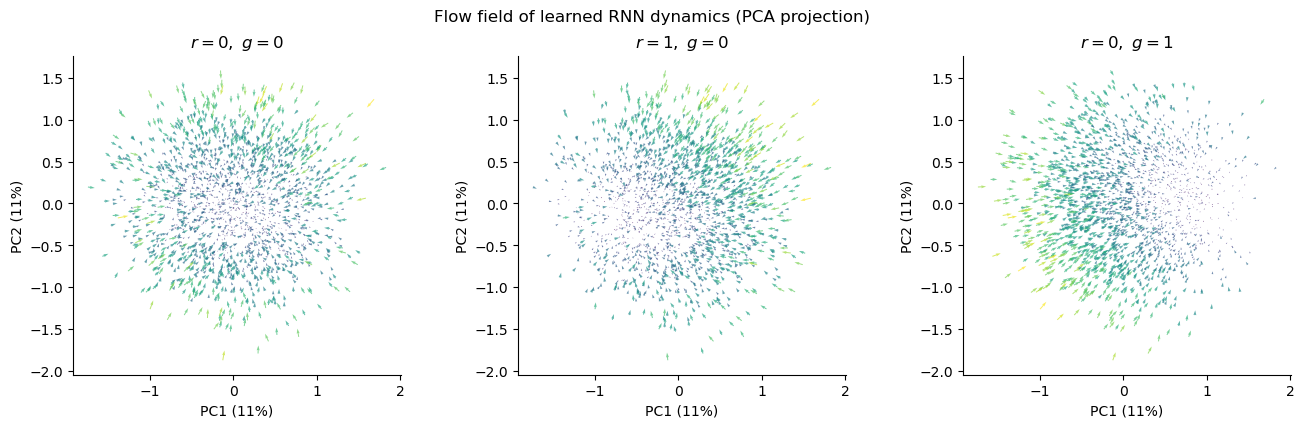

: 

In [ ]:
# ── Plot: flow field of learned RNN dynamics ─────────────────────────────────
W_rec_np  = np.array(params['W_rec'])   # (H, H)
w_in_np   = np.array(params['w_in'])    # (H,)
h_star_np = np.array(params['h_star'])  # (H,)
b_np      = np.array(params['b'])       # (H,)

def rnn_step(h, r=0.0, g=0.0):
    return np.clip(W_rec_np @ h + w_in_np * r + g * h_star_np + b_np, -1.0, 1.0)

FLOW_CONDITIONS = [
    ('$r=0,\\ g=0$', 0.0, 0.0),
    ('$r=1,\\ g=0$', 1.0, 0.0),
    ('$r=0,\\ g=1$', 0.0, 1.0),
]

rng_ff = np.random.default_rng(42)
N_FF   = 2_000
h_samp = rng_ff.uniform(-1.0, 1.0, size=(N_FF, HIDDEN_SIZE))

if HIDDEN_SIZE == 2:
    # ── 2-D: direct streamplot ──────────────────────────────────────────────
    N_GRID = 25
    hx = np.linspace(-1, 1, N_GRID)
    hy = np.linspace(-1, 1, N_GRID)
    HX, HY = np.meshgrid(hx, hy)

    fig, axes = plt.subplots(1, len(FLOW_CONDITIONS), figsize=(4.5 * len(FLOW_CONDITIONS), 4.2))
    for ax, (label, r_val, g_val) in zip(axes, FLOW_CONDITIONS):
        H_grid = np.stack([HX.ravel(), HY.ravel()], axis=1)   # (N², 2)
        H_new  = np.array([rnn_step(h, r_val, g_val) for h in H_grid])
        dH     = H_new - H_grid
        U = dH[:, 0].reshape(N_GRID, N_GRID)
        V = dH[:, 1].reshape(N_GRID, N_GRID)
        speed = np.sqrt(U**2 + V**2)
        ax.streamplot(hx, hy, U, V, color=speed, cmap='viridis', density=1.4, linewidth=0.9)
        ax.set_xlim(-1, 1); ax.set_ylim(-1, 1)
        ax.set_xlabel('$h_0$'); ax.set_ylabel('$h_1$')
        ax.set_title(label); ax.set_aspect('equal')
        ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle('Flow field of learned RNN dynamics')

else:
    # ── N-D: project onto top-2 PCA directions ─────────────────────────────
    h_mu   = h_samp.mean(axis=0)
    _, _, Vt = np.linalg.svd(h_samp - h_mu, full_matrices=False)
    PCs    = Vt[:2]   # (2, H)

    def project(h_arr):
        return (h_arr - h_mu) @ PCs.T   # (N, 2)

    # Explained variance ratio
    all_h_c = h_samp - h_mu
    total_var = np.sum(all_h_c**2)
    evr = [np.sum((all_h_c @ PCs[i])**2) / total_var for i in range(2)]

    fig, axes = plt.subplots(1, len(FLOW_CONDITIONS), figsize=(4.5 * len(FLOW_CONDITIONS), 4.2))
    for ax, (label, r_val, g_val) in zip(axes, FLOW_CONDITIONS):
        h_new  = np.array([rnn_step(h, r_val, g_val) for h in h_samp])
        h_pc   = project(h_samp)
        hn_pc  = project(h_new)
        dh_pc  = hn_pc - h_pc
        speed  = np.linalg.norm(dh_pc, axis=1)
        sc = ax.quiver(h_pc[:, 0], h_pc[:, 1], dh_pc[:, 0], dh_pc[:, 1],
                       speed, cmap='viridis', alpha=0.7, scale=None, angles='xy',
                       scale_units='xy', width=0.003)
        ax.set_xlabel(f'PC1 ({evr[0]*100:.0f}%)')
        ax.set_ylabel(f'PC2 ({evr[1]*100:.0f}%)')
        ax.set_title(label); ax.set_aspect('equal')
        ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle('Flow field of learned RNN dynamics (PCA projection)')

fig.tight_layout()
plt.show()